In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

df = pd.concat([pd.read_csv("final.csv")], ignore_index=True)
df = df[df["instance"] == "tree"]
solvers_to_remove = [
    "ilp_arc_95",
    "ilp_arc_heuristic_placement",
    "ilp_arc_heuristic_warm_start",
    "ilp_arc_rl_warm_start",
]
df = df[~df["solver"].isin(solvers_to_remove)]
df.reset_index(drop=True, inplace=True)
df.head()

,instance,solver,users,neighbors,groups,score,runtime,buildtime
0,tree,ilp_arc,10,1,4,70.0,2.217680,1.775872
1,tree,heuristic,10,1,4,20.0,0.408113,0.000000
2,tree,PPO,10,1,4,52.0,36.246668,0.000000
3,tree,ilp_arc,20,1,4,140.0,2.829193,1.700209
4,tree,heuristic,20,1,4,40.0,1.466816,0.000000


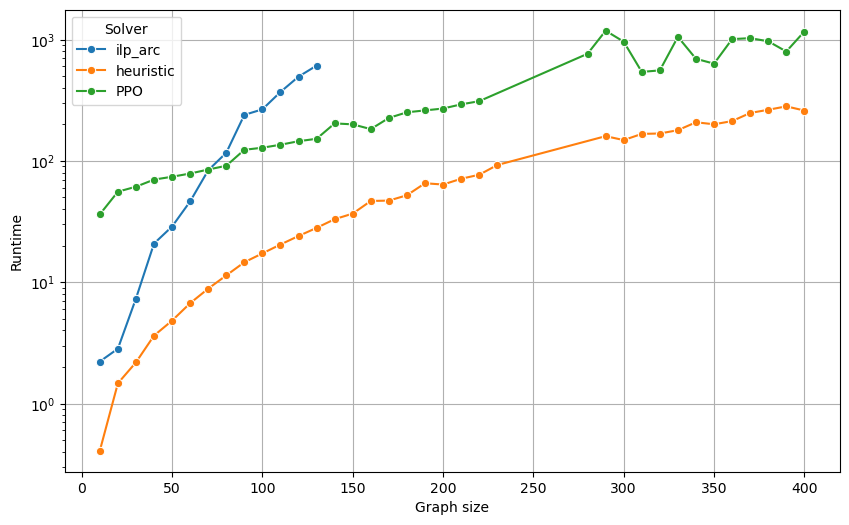

In [7]:
plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x="users", y="runtime", hue="solver", marker="o")
# plt.title("Runtime vs Users for Different Solvers")
plt.xlabel("Graph size")
plt.ylabel("Runtime")
plt.yscale("log")
plt.legend(title="Solver")
plt.grid(True)
plt.show()

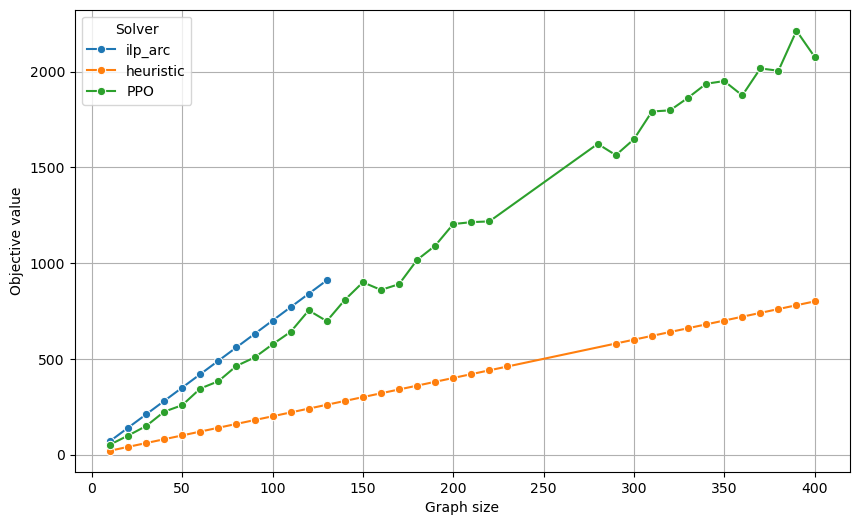

In [8]:
plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x="users", y="score", hue="solver", marker="o")
# plt.title("Runtime vs Users for Different Solvers")
plt.xlabel("Graph size")
plt.ylabel("Objective value")
# plt.yscale("log")
plt.legend(title="Solver")
plt.grid(True)
plt.show()

In [9]:
df = df[df['users'] <= 220]

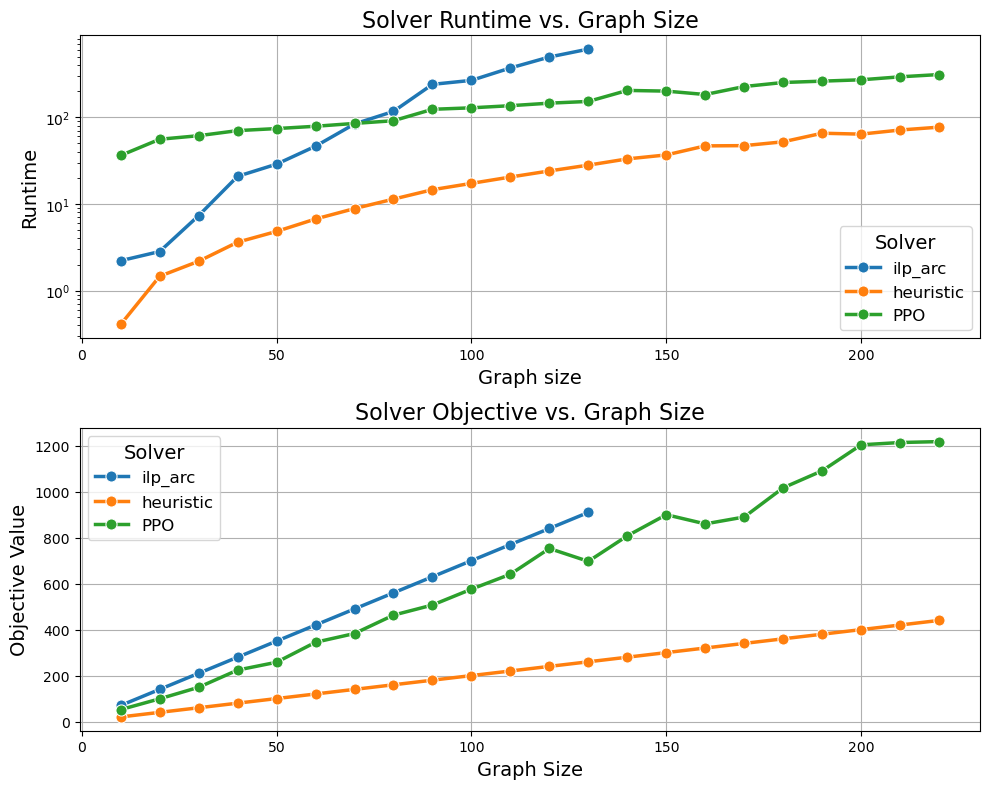

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))

# Common parameters for the plots
common_params = {
    'data': df,
    'x': 'users',
    'hue': 'solver',
    'marker': 'o',
    'linewidth': 2.5,  # Thicker lines
    'markersize': 8,   # Larger markers
    'ax': None
}

# Plot runtime vs users
common_params['ax'] = axes[0]
sns.lineplot(y='runtime', **common_params)
axes[0].set_title("Solver Runtime vs. Graph Size", fontsize=16)
axes[0].set_xlabel("Graph size", fontsize=14)
axes[0].set_ylabel("Runtime", fontsize=14)
axes[0].set_yscale("log")
axes[0].legend(title="Solver", fontsize=12, title_fontsize=14)
axes[0].grid(True)

# Plot score vs users
common_params['ax'] = axes[1]
sns.lineplot(y='score', **common_params)
axes[1].set_title("Solver Objective vs. Graph Size", fontsize=16)
axes[1].set_xlabel("Graph Size", fontsize=14)
axes[1].set_ylabel("Objective Value", fontsize=14)
axes[1].legend(title="Solver", fontsize=12, title_fontsize=14)
axes[1].grid(True)
axes[1].grid(True)

# Adjust layout and save the figure
plt.tight_layout()
plt.savefig('final_tree.pdf', bbox_inches='tight')
plt.show()